In [1]:

# Instala a biblioteca pymoo, utilizada para executar algoritmos de otimização
!pip install pymoo

# Instala a biblioteca matplotlib, utilizada para criar gráficos
!pip install matplotlib

# Instala a biblioteca numpy, utilizada para cálculos matemáticos e vetores
!pip install numpy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 14.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 13.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


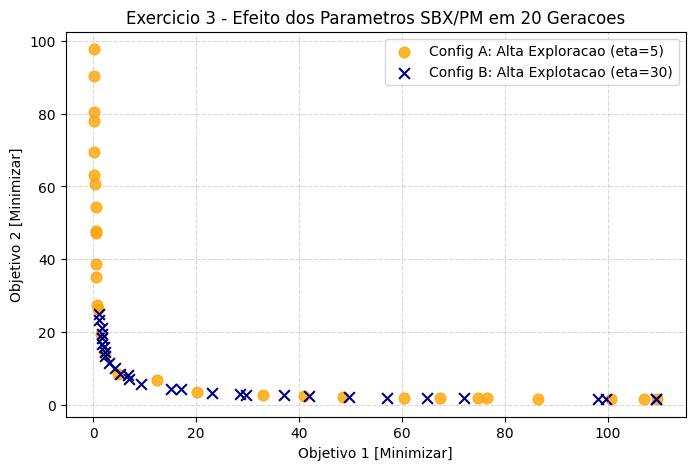

In [3]:

# ============================================================
# QUESTÃO 3 - OPERADORES GENÉTICOS
# EXPLORAÇÃO VS. EXPLOTAÇÃO
# ============================================================

# 1. Importação das bibliotecas

import numpy as np
# Biblioteca utilizada para cálculos matemáticos e criação de arrays.

import matplotlib.pyplot as plt
# Biblioteca utilizada para criar gráficos.

from pymoo.core.problem import ElementwiseProblem
# Permite criar o problema de otimização.

from pymoo.algorithms.moo.nsga2 import NSGA2
# Importa o algoritmo genético NSGA-II.

from pymoo.operators.crossover.sbx import SBX
# Importa o operador de cruzamento entre soluções.

from pymoo.operators.mutation.pm import PM
# Importa o operador de mutação.

from pymoo.optimize import minimize
# Função responsável por executar a otimização.


# 2. Criação do problema matemático

class BenchmarkTradeoffProblem(ElementwiseProblem):

    def __init__(self):

        super().__init__(
            n_var=2,
            # O problema possui duas variáveis: x1 e x2.

            n_obj=2,
            # O problema possui dois objetivos para minimizar.

            xl=np.array([0.1, 0.1]),
            # Define o valor mínimo permitido para x1 e x2.

            xu=np.array([10.0, 10.0])
            # Define o valor máximo permitido para x1 e x2.
        )

    def _evaluate(self, x, out, *args, **kwargs):

        f1 = x[0]**2 + x[1]
        # Calcula o primeiro objetivo.

        f2 = (10.0 / x[0]) + (5.0 / x[1])
        # Calcula o segundo objetivo.

        out["F"] = [f1, f2]
        # Entrega os dois resultados ao algoritmo.


# 3. Criação do problema

problem = BenchmarkTradeoffProblem()
# Cria uma instância do problema matemático.


# 4. Configuração A - Exploração agressiva

alg_exploracao = NSGA2(

    pop_size=30,
    # Cria uma população de 30 soluções.

    crossover=SBX(prob=0.9, eta=5),
    # Cruzamento com probabilidade de 90%.
    # eta=5 favorece uma exploração mais ampla.

    mutation=PM(prob=0.5, eta=5)
    # Mutação com probabilidade de 50%.
    # eta=5 também favorece maior diversidade.
)


# 5. Configuração B - Explotação refinada

alg_explotacao = NSGA2(

    pop_size=30,
    # Também utiliza 30 soluções.

    crossover=SBX(prob=0.9, eta=30),
    # Cruzamento com eta=30, mais concentrado nos pais.

    mutation=PM(prob=0.05, eta=30)
    # Mutação com probabilidade de 5%.
    # Favorece alterações menores e menos frequentes.
)


# 6. Execução da configuração A

res_a = minimize(
    problem,
    alg_exploracao,
    ('n_gen', 20),
    seed=42
)
# Executa a configuração A durante 20 gerações.
# seed=42 permite reproduzir a execução.


# 7. Execução da configuração B

res_b = minimize(
    problem,
    alg_explotacao,
    ('n_gen', 20),
    seed=42
)
# Executa a configuração B durante 20 gerações.


# 8. Criação do gráfico comparativo

plt.figure(figsize=(8, 5))
# Define o tamanho do gráfico.

plt.scatter(
    res_a.F[:, 0],
    res_a.F[:, 1],
    color='orange',
    label='Config A: Alta Exploracao (eta=5)',
    alpha=0.8,
    s=60
)
# Mostra os resultados da configuração A em laranja.

plt.scatter(
    res_b.F[:, 0],
    res_b.F[:, 1],
    color='navy',
    marker='x',
    label='Config B: Alta Explotacao (eta=30)',
    s=60
)
# Mostra os resultados da configuração B em azul.


plt.title("Exercicio 3 - Efeito dos Parametros SBX/PM em 20 Geracoes")
# Define o título do gráfico.

plt.xlabel("Objetivo 1 [Minimizar]")
# Nome do eixo horizontal.

plt.ylabel("Objetivo 2 [Minimizar]")
# Nome do eixo vertical.

plt.legend()
# Mostra a legenda das duas configurações.

plt.grid(True, linestyle='--', alpha=0.5)
# Adiciona linhas de referência ao gráfico.

plt.show()
# Exibe o gráfico.
